         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

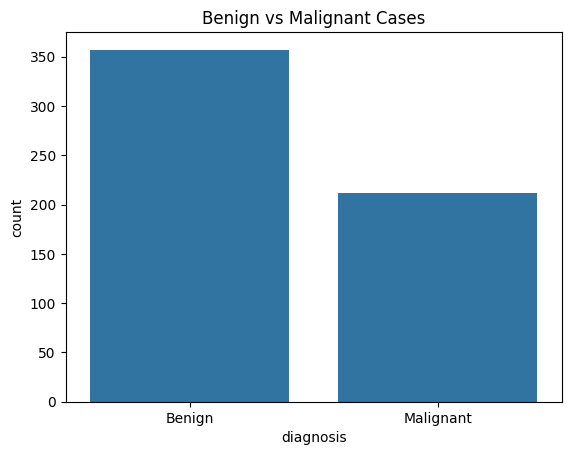

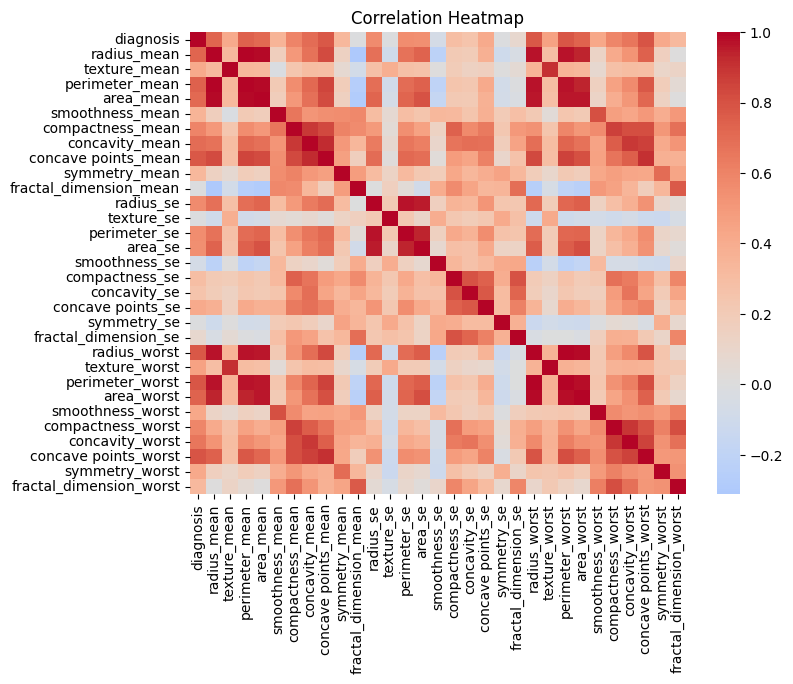

Feature shape: (569, 30)
Target shape: (569,)

Feature names:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']
Training samples: 455
Testing samples: 114
Training percentage: 79.96485061511423
Testing percentage: 20.035149384885763
Selected features:
radius_mean
perimeter_mean
area_mean
concavity_mean
concave points_mean
radius_worst
perimeter_worst
area_worst
concavity_worst
concave points_worst

Top 10 features:
                 Feature     F_Score
27  concave points_worst  733.724933
22       pe

In [11]:
# Part 1: Import libraries and load dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    log_loss,
    brier_score_loss,
    r2_score,
    mean_squared_error
)

# Load dataset
df = pd.read_csv("breast_cancer.csv")

# Display first five rows
print(df.head())

# Display dataset shape
print("Dataset shape:", df.shape)


# Part 2: Data cleaning

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates().copy()

# Remove unnecessary columns
df = df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Remove rows where diagnosis is missing
df = df.dropna(subset=["diagnosis"]).copy()

# Convert diagnosis into numbers
# B = 0 (Benign)
# M = 1 (Malignant)

df["diagnosis"] = (
    df["diagnosis"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({"B": 0, "M": 1})
)

# Remove invalid target values
df = df.dropna(subset=["diagnosis"]).copy()
df["diagnosis"] = df["diagnosis"].astype(int)

print("\nCleaned dataset shape:", df.shape)
print(df.head())


# Part 3: Exploratory Data Analysis

# Statistical summary
print("Statistical summary:")
print(df.describe().T)

# Mean values
print("\nMean:")
print(df.mean(numeric_only=True))

# Median values
print("\nMedian:")
print(df.median(numeric_only=True))

# Standard deviation
print("\nStandard deviation:")
print(df.std(numeric_only=True))

# Diagnosis distribution
sns.countplot(data=df, x="diagnosis")
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.title("Benign vs Malignant Cases")
plt.show()
# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(
    df.corr(numeric_only=True),
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap")
plt.show()
# Part 4: Separate X and y
# X contains tumor measurement features
X = df.drop(columns=["diagnosis"])

# y contains the diagnosis
y = df["diagnosis"]

# Keep only numerical features
X = X.select_dtypes(include=np.number)

# Remove columns that are completely empty
X = X.dropna(axis=1, how="all")

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature names:")
print(X.columns.tolist())
# Part 5: Train-test split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training percentage:", len(X_train) / len(X) * 100)
print("Testing percentage:", len(X_test) / len(X) * 100)

# Part 6: Feature selection and preprocessing
#the 10 features are selected using a method called SelectKBest with ANOVA F-test (f_classif).
number_of_features = min(10, X_train.shape[1])

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("feature_selection", SelectKBest(
        score_func=f_classif,
        k=number_of_features
    )),

    ("scaler", StandardScaler()),

    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# Train the complete model
model.fit(X_train, y_train)

# Get selected feature names
selected_mask = model.named_steps[
    "feature_selection"
].get_support()

selected_features = X_train.columns[selected_mask]

print("Selected features:")
for feature in selected_features:
    print(feature)

# Display feature scores
scores = model.named_steps[
    "feature_selection"
].scores_

feature_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "F_Score": scores
}).sort_values(
    "F_Score",
    ascending=False
)

print("\nTop 10 features:")
print(feature_scores.head(10))

# Part 7: Predictions and accuracy

# Predict training and testing data
y_train_pred = model.predict(X_train)
y_pred = model.predict(X_test)

# Get probability of malignant diagnosis
y_probability = model.predict_proba(X_test)[:, 1]

# Calculate accuracy
train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

test_accuracy = accuracy_score(
    y_test,
    y_pred
)

# Calculate test error
test_error = 1 - test_accuracy

print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)
print("Test error rate:", test_error)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))


# Part 8: Statistical metrics

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

auc = roc_auc_score(y_test, y_probability)

loss = log_loss(y_test, y_probability)

brier = brier_score_loss(y_test, y_probability)

rmse = np.sqrt(mean_squared_error(y_test, y_probability))
# R² calculated on predicted probabilities
r2 = r2_score(y_test, y_probability)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("ROC-AUC:", auc)
print("Log loss:", loss)
print("Brier score:", brier)
print("Probability RMSE:", rmse)
print("R² score:", r2)

